In [1]:
import sys
import os
# Set up project root directory


notebook_dir = os.getcwd()  # Current working directory (assumes running from notebooks/)
project_path = os.path.normpath(os.path.join(notebook_dir, ".."))  # Move up to project root
dima_path = os.path.normpath(os.path.join(project_path, "dima"))  # Move up to project root

for item in sys.path:
    print(item)


if project_path not in sys.path:  # Avoid duplicate entries
    sys.path.append(project_path)
    print(project_path)
if dima_path not in sys.path:
    sys.path.insert(0,dima_path)
    print(dima_path)


/opt/conda/envs/apog_penv/lib/python311.zip
/opt/conda/envs/apog_penv/lib/python3.11
/opt/conda/envs/apog_penv/lib/python3.11/lib-dynload

/opt/conda/envs/apog_penv/lib/python3.11/site-packages
/acsmdc
/acsmdc/dima


## Explore Datasets in HDF5 File

* Use the HDF5 data manager object to load the metadata of the HDF5 file's datasets.
* Display metadata and identify dataset of interest for next step.
* Excecute the cell.


In [2]:
import dima.src.hdf5_ops as dataOps

CAMPAIGN_DATA_FILE = "../data/collection_PAY_2024_2025-05-19_2025-05-19.h5"
APPEND_DIR = os.path.splitext(CAMPAIGN_DATA_FILE)[0]

path_to_data_file = CAMPAIGN_DATA_FILE
dataManager = dataOps.HDF5DataOpsManager(path_to_data_file)

dataManager.load_file_obj()
dataManager.extract_and_load_dataset_metadata()
dataset_metadata_df = dataManager.dataset_metadata_df

print(dataset_metadata_df.head(n=15))
dataManager.unload_file_obj()

                                        dataset_name  parent_instrument  \
0  ACSM_TOFWARE/2024/ACSM_PAY_2024_meta.txt/data_...  ACSM_TOFWARE/2024   
1  ACSM_TOFWARE/2024/ACSM_PAY_2024_timeseries.txt...  ACSM_TOFWARE/2024   
2    ACSM_TOFWARE/2024/Org_data_valid.csv/data_table  ACSM_TOFWARE/2024   
3     ACSM_TOFWARE/2024/Org_err_valid.csv/data_table  ACSM_TOFWARE/2024   
4      ACSM_TOFWARE/2024/Org_mz_valid.csv/data_table  ACSM_TOFWARE/2024   
5    ACSM_TOFWARE/2024/Org_time_valid.csv/data_table  ACSM_TOFWARE/2024   

                    parent_file  
0        ACSM_PAY_2024_meta.txt  
1  ACSM_PAY_2024_timeseries.txt  
2            Org_data_valid.csv  
3             Org_err_valid.csv  
4              Org_mz_valid.csv  
5            Org_time_valid.csv  


## Specify Dataset and Flags Dataset to Be Visualized Based on Dataset Index

* Specify the dataset index based on previous step.
* Excecute the cell.

In [3]:
import pandas as pd

# Specify diagnostic variables and the associated flags 
dataset_idx = 0
dataset_name = dataset_metadata_df['dataset_name'][dataset_idx]
parent_instrument = dataset_metadata_df['parent_instrument'][dataset_idx]

# Infer expected flags dataset name, which is associated with the above defined dataset

flags_dataset_name = dataset_name.split(sep='/')
flags_dataset_name[0] = f'{flags_dataset_name[0]}_flags'
flags_dataset_name = '/'.join(flags_dataset_name)

print(dataset_name)
print(flags_dataset_name)

# Visualize dataset column names and identify the time variable and y variable channels for next step
try:
    dataManager.load_file_obj()
    dataset_df = dataManager.extract_dataset_as_dataframe(dataset_name)
    print(dataset_df.columns)
except Exception as e:
    print(f"Exception occurred while loading dataset: {e}")
finally:
    dataManager.unload_file_obj()

ACSM_TOFWARE/2024/ACSM_PAY_2024_meta.txt/data_table
ACSM_TOFWARE_flags/2024/ACSM_PAY_2024_meta.txt/data_table
Index(['t_base', 'VaporizerTemp_C', 'HeaterBias_V', 'FlowRefWave',
       'FlowRate_mb', 'FlowRate_ccs', 'FilamentEmission_mA', 'Detector_V',
       'AnalogInput06_V', 'ABRefWave', 'ABsamp', 'ABCorrFact'],
      dtype='object')


## Visualize Diagnostic Variables Alongside the Associated Flags

* Ensure that `dataset_name` and `flags_dataset_name` are properly defined in the previous step.
* Build a list `diagnostic_variables` with the variable names you would like to visualize, based on the previously displayed options.
* Define `time_var` with the time variable name from the previously displayed variable names.
* Execute the cell.


y axis range: [590, 610]


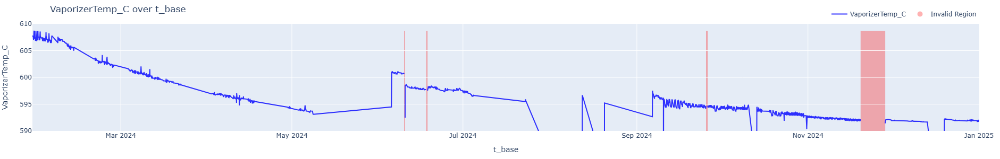

y axis range: [0, 100]


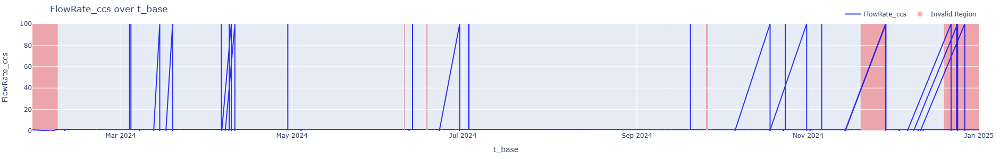

y axis range: [0.972222, 57353.1]


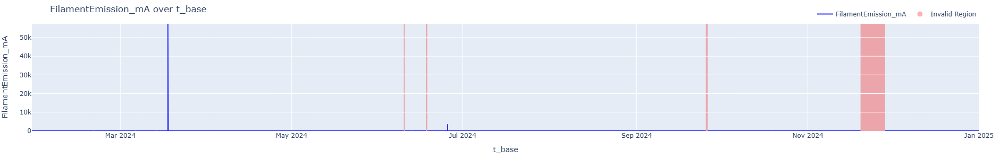

y axis range: [79362.2, 477481.0]


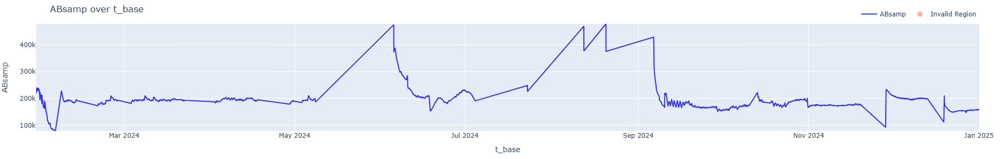

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pipelines.steps.visualize_datatable_vars as vis


variable_sets = {
    "diagnostic": {
        "variables": [
            'VaporizerTemp_C', 'FlowRate_ccs', 'FilamentEmission_mA', 'ABsamp'
        ],
        "time_var": "t_base"
    },
    "cpc": {
        "variables": ["conc"],
        "time_var": "end_time"
    },
    "species": {
        "variables": ['Chl_11000', 'NH4_11000', 'SO4_11000', 'NO3_11000', 'Org_11000'],
        "time_var": "t_start_Buf"
    }
}

# Choose one: "diagnostic", "cpc", or "species"
selected_set = "diagnostic"

variables = variable_sets[selected_set]["variables"]
time_var = variable_sets[selected_set]["time_var"]

yaxis_range_dict = {'FlowRate_ccs' : [0,100],
                    'VaporizerTemp_C': [590,610]}
figs = vis.visualize_table_variables(path_to_data_file, 
                                        dataset_name, 
                                        flags_dataset_name,
                                        x_var  = time_var,
                                        y_vars = variables,
                                        yaxis_range_dict = yaxis_range_dict)



